# Adult Income Classification — k-Nearest Neighbors

A scikit-learn pipeline with mixed-type preprocessing, stratified cross-validation, hyperparameter search, learning curves, and holdout evaluation. The saved run reports 84.37% accuracy and 0.893 ROC-AUC.

## k-NN Classifier for the UCI "Adult" Dataset

This notebook trains and evaluates a **k-Nearest Neighbors (k-NN)** classifier on the **UCI Adult dataset**, performing model selection and generating diagnostic visualizations.

###  Key steps
- Selects the best *k* value using **cross-validation** (`GridSearchCV`)
- Evaluates performance on a **held-out test set**
- Produces diagnostic plots:
  - Accuracy vs *k*
  - Cross-validation boxplots
  - ROC curve
  - Precision–Recall curve
  - Learning curve
  - Confusion matrix
- Saves the **best pipeline** to disk for reuse

---

##  About the k-NN Classifier

**kNN** is one of the simplest machine learning algorithms.

It performs **no learning** in the training phase — instead, it simply **stores all training examples** (feature vectors and their labels).

When a new example is introduced, the algorithm:

1. **Computes the distance** (usually Euclidean) from the new point to all training samples.  
2. **Selects the *k* closest** training points — the *neighbors*.  
3. **Counts their labels** (or averages them, for regression).  
4. **Predicts** the most frequent label among those *k* neighbors.

---

 In short, kNN is a **lazy learner** that relies entirely on the structure of the training data to make predictions.

In [1]:
# -------------------------
# 0) Import libraries
# -------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay, average_precision_score
)
import joblib

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['grid.alpha'] = 0.3

## Data loading & quick exploration

We load the Adult dataset. If you already have a local CSV, set `data_path`. Otherwise the notebook tries the common UCI URL.

In [2]:
# -------------------------
# 1) Data load & data preparation
# -------------------------

data_path = None
uci_data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

column_names = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

def load_adult(data_path=None):
    if data_path and os.path.exists(data_path):
        try:
            df = pd.read_csv(data_path, header=None, names=column_names, sep=r",\s*", engine="python")
        except Exception:
            df = pd.read_csv(data_path, header=None, names=column_names)
    else:
        print("Downloading Adult dataset from UCI (adult.data)...")
        df = pd.read_csv(uci_data_url, header=None, names=column_names, sep=r",\s*", engine="python")
    # strip strings, replace '?' with NaN, clean income trailing dots
    df = df.map(lambda x: x.strip() if isinstance(x, str) else x)
    df = df.replace('?', np.nan)
    df['income'] = df['income'].str.replace(r'\.', '', regex=True).str.strip()
    return df

df = load_adult(data_path)
print("Loaded dataset shape:", df.shape)
print(df.head())

Loaded dataset shape: (32561, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-States  <=50K  
1       

## Prepare features and split

- We'll separate numeric and categorical features.
- Use `train_test_split` with stratification by the target to keep class balance.

In [3]:
# -------------------------
# 2) Prepare X, y and do holdout split
# -------------------------

X = df.drop(columns=['income'])
y = df['income'].replace({'<=50K': 0, '>50K': 1, '<=50K.': 0, '>50K.': 1}).astype(int)

# Reserve 20% for final testing (empirical error)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (26048, 14) Test shape: (6513, 14)


## Preprocessing pipeline

We create a `ColumnTransformer`:
- Standard scale numeric features (`StandardScaler`)
- One-hot encode categorical features (`OneHotEncoder`, handle unknown categories at transform time)

In [4]:
# -------------------------
# 3) Preprocessing pipelines
# -------------------------
# Detect numeric and categorical columns

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='drop')

Numeric features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [ ]:
# -------------------------
# 3b) Apply preprocessing to train/test splits
# -------------------------

preprocessor.fit(X_train)

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)


## k-NN pipeline and hyperparameter grid

We build a full pipeline: preprocessing -> k-NN classifier. Then define a grid of `n_neighbors`, `weights` and `p` (distance metric).
We use `StratifiedKFold` for cross-validation to preserve class distribution.

In [5]:
# -------------------------
# 4) k-NN pipeline + hyperparameter grid
# -------------------------

knn = KNeighborsClassifier()
pipe = Pipeline(steps=[('preprocessor', preprocessor), ('knn', knn)])

param_grid = {
    'knn__n_neighbors': list(range(1, 31, 2)),     # 1,3,5,...,29
    'knn__weights': ['uniform', 'distance'],       # This determines how the neighbors' votes are weighted. 'uniform' means all neighbors have equal say, while 'distance' means closer neighbors have more influence.
    'knn__p': [1, 2]                               # 1 = Manhattan, 2 = Euclidean
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1) # It will systematically try every combination of hyperparameters defined
                                                                            # ' n_jobs=-1' tells it to use all available processor cores to speed up the process.

In [6]:
# -------------------------
# 5) Fit grid search on training set
# -------------------------

print("Starting GridSearchCV ...")
grid.fit(X_train, y_train)
print("Grid search done.")
print("Best params:", grid.best_params_)
print("Best cross-validated accuracy (mean):", grid.best_score_)

Starting GridSearchCV ...
Grid search done.
Best params: {'knn__n_neighbors': 17, 'knn__p': 2, 'knn__weights': 'uniform'}
Best cross-validated accuracy (mean): 0.8417156044333426


## Evaluate the best estimator on the holdout test set

Compute:
- Test accuracy and empirical error rate
- Classification report and confusion matrix
- ROC curve and AUC (computed from predicted probabilities)

## How the ROC curve is computed

- For each threshold `t` applied to the positive-class probability score:
  - Predicted positive if `score >= t`, otherwise negative.
  - Compute True Positive Rate (TPR = TP/(TP+FN)) and False Positive Rate (FPR = FP/(FP+TN)).
- ROC plots TPR vs FPR while the threshold `t` varies from high to low.
- AUC (area under the ROC curve) summarizes classifier separability: 1.0 = perfect, 0.5 = random.
- For k-NN we used `predict_proba(...)[:,1]` as the score.

Test accuracy: 0.8437
Empirical error rate (1 - accuracy): 0.1563

Classification report (test set):
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      4945
        >50K       0.70      0.61      0.65      1568

    accuracy                           0.84      6513
   macro avg       0.79      0.76      0.78      6513
weighted avg       0.84      0.84      0.84      6513



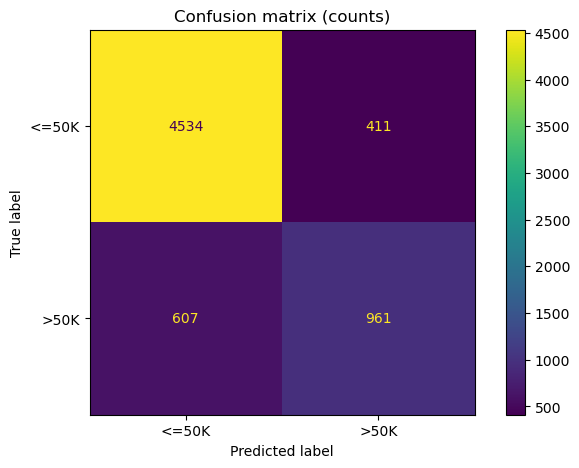

ROC AUC (test): 0.8927760209240421


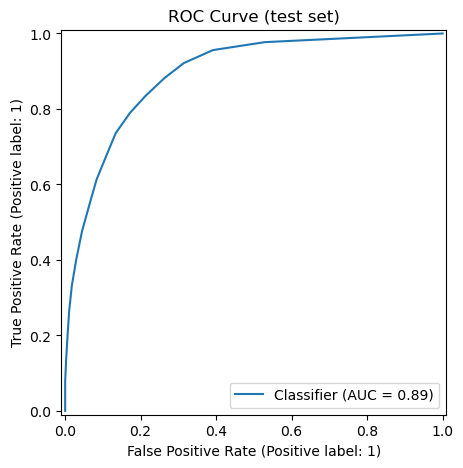

Average precision (PR AUC): 0.7265665619149465


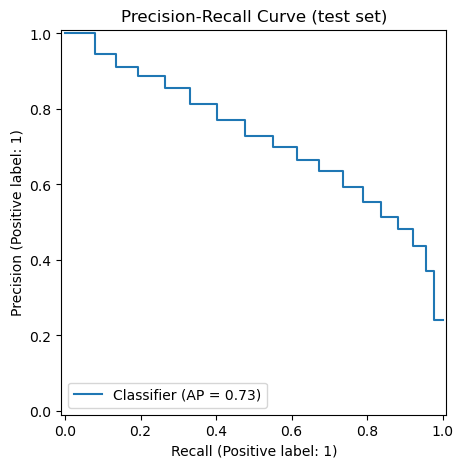

In [7]:
# -------------------------
# 6) Evaluate best estimator on holdout test set
# -------------------------

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
empirical_error_rate = 1.0 - test_acc

print(f"Test accuracy: {test_acc:.4f}")
print(f"Empirical error rate (1 - accuracy): {empirical_error_rate:.4f}")
print("\nClassification report (test set):")
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50K', '>50K'])
disp.plot()
plt.title("Confusion matrix (counts)")
plt.show()

# ROC and PR curves (k-NN supports predict_proba)
if hasattr(best_model, "predict_proba"):
    y_prob = best_model.predict_proba(X_test)[:, 1]
    try:
        roc_auc = roc_auc_score(y_test, y_prob)
        print("ROC AUC (test):", roc_auc)
        RocCurveDisplay.from_predictions(y_test, y_prob)
        plt.title("ROC Curve (test set)")
        plt.show()

        ap = average_precision_score(y_test, y_prob)
        print("Average precision (PR AUC):", ap)
        PrecisionRecallDisplay.from_predictions(y_test, y_prob)
        plt.title("Precision-Recall Curve (test set)")
        plt.show()
    except Exception as e:
        print("Could not compute ROC/PR:", e)
else:
    print("Best model doesn't support predict_proba (skipping ROC/PR)")

## Inspect cross-validation results

We will convert the `GridSearchCV` `cv_results_` into a DataFrame and visualize mean test scores across `n_neighbors`.

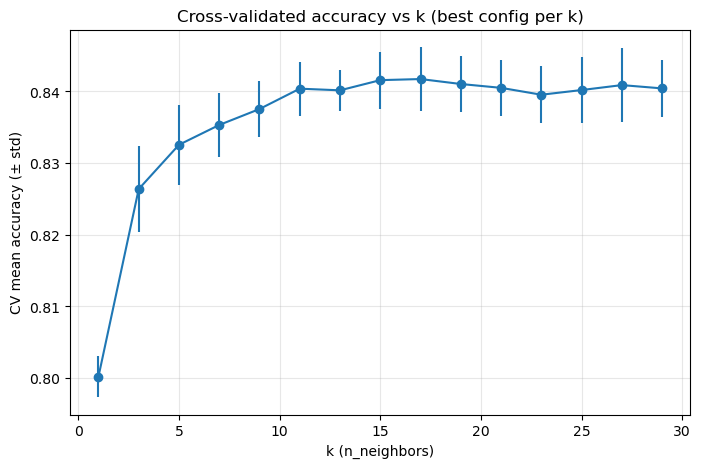

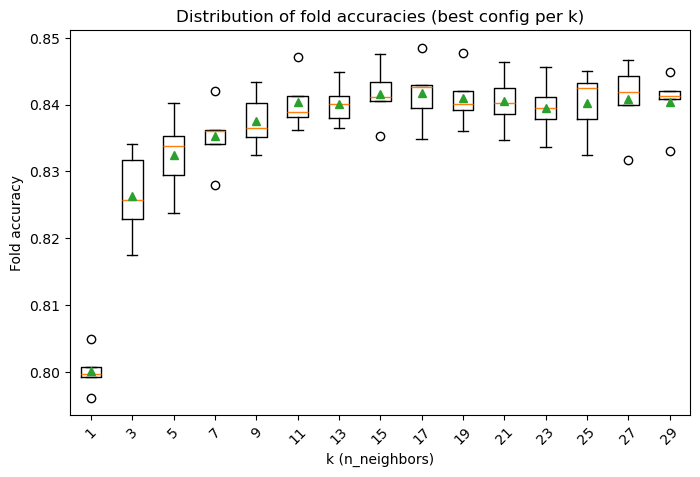

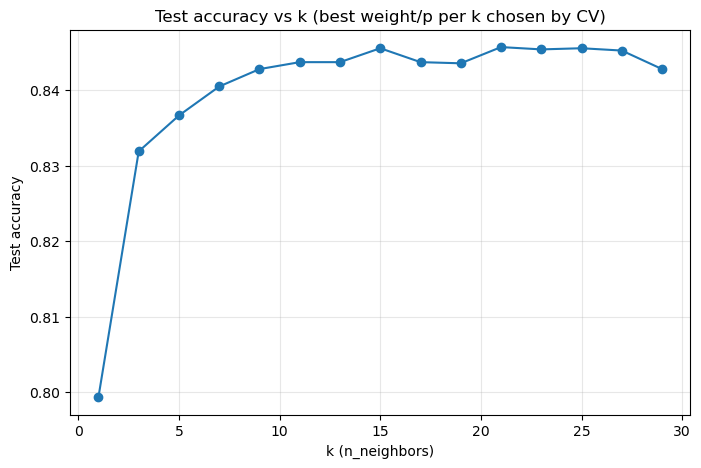

In [8]:
# -------------------------
# 7) Inspect CV results and create plots
# -------------------------

results = pd.DataFrame(grid.cv_results_)
results['k'] = results['param_knn__n_neighbors'].astype(int)
results['weights'] = results['param_knn__weights'].astype(str)
results['p'] = results['param_knn__p'].astype(int)

# For each k, take the best (highest mean_test_score) configuration among weights/p
best_per_k_idx = results.groupby('k')['mean_test_score'].idxmax()
best_per_k = results.loc[best_per_k_idx].sort_values('k')

# Plot mean CV accuracy ± std for best config per k
plt.errorbar(best_per_k['k'], best_per_k['mean_test_score'], yerr=best_per_k['std_test_score'], marker='o', linestyle='-')
plt.xlabel('k (n_neighbors)')
plt.ylabel('CV mean accuracy (± std)')
plt.title('Cross-validated accuracy vs k (best config per k)')
plt.grid(True)
plt.show()

# Boxplot of fold accuracies for each k (best config per k)
score_cols = [c for c in results.columns if c.startswith('split') and c.endswith('_test_score')]
box_data = [best_per_k.loc[idx, score_cols].values for idx in best_per_k.index]
plt.boxplot(box_data, labels=best_per_k['k'].astype(str), showmeans=True)
plt.xlabel('k (n_neighbors)')
plt.ylabel('Fold accuracy')
plt.title('Distribution of fold accuracies (best config per k)')
plt.xticks(rotation=45)
plt.show()

# Test accuracy vs k: retrain best weight/p for each k and evaluate on the holdout test set
ks = best_per_k['k'].tolist()
test_accuracies = []
for _, row in best_per_k.iterrows():
    k_val = int(row['param_knn__n_neighbors'])
    w = row['param_knn__weights']
    p_val = int(row['param_knn__p'])
    # make a fresh pipeline and fit on full training data
    temp_pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('knn', KNeighborsClassifier(n_neighbors=k_val, weights=w, p=p_val))
    ])
    temp_pipe.fit(X_train, y_train)
    test_accuracies.append(accuracy_score(y_test, temp_pipe.predict(X_test)))

plt.plot(ks, test_accuracies, marker='o')
plt.xlabel('k (n_neighbors)')
plt.ylabel('Test accuracy')
plt.title('Test accuracy vs k (best weight/p per k chosen by CV)')
plt.grid(True)
plt.show()

## Learning curve

A learning curve shows training and cross-validation performance as a function of training set size. It helps detect underfitting or overfitting.

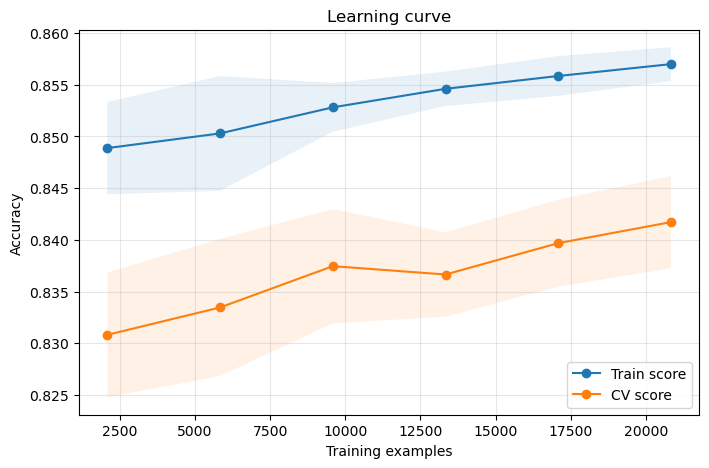

In [9]:
# -------------------------
# 8) Learning curve (train size vs train/CV accuracy)
# -------------------------


train_sizes = np.linspace(0.1, 1.0, 6)
train_sizes_abs, train_scores, val_scores = learning_curve(
    best_model, X_train, y_train, train_sizes=train_sizes, cv=cv,
    scoring='accuracy', n_jobs=-1, shuffle=True, random_state=42
)
train_mean = train_scores.mean(axis=1); train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1); val_std = val_scores.std(axis=1)

plt.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.1)
plt.plot(train_sizes_abs, train_mean, 'o-', label='Train score')
plt.plot(train_sizes_abs, val_mean, 'o-', label='CV score')
plt.xlabel('Training examples')
plt.ylabel('Accuracy')
plt.title('Learning curve')
plt.legend()
plt.grid(True)
plt.show()

## Final notes & next steps

- This pipeline demonstrates a reproducible training and evaluation workflow for k-NN.
- Potential improvements:
  - Address class imbalance using resampling or class weights (k-NN doesn't accept `class_weight`, so resampling is the practical approach).
  - Use more advanced encodings (target encoding, embedding) for categorical features with very high cardinality (e.g., native_country).
  - Experiment with dimensionality reduction (PCA) before k-NN to speed up inference.
  - Consider approximate nearest neighbors libraries (e.g., `faiss`, `annoy`) for large datasets.
